# Subgroup Performance in Healthcare Risk Models
### Evaluation, Calibration Audits, and Scalable Fairness Mitigation in 30-Day Hospital Readmission Prediction
**Course:** Big Data Systems & Responsible AI Engineering (BDSRAE) - PES University  
**Instructor:** Dr. Manjula Devananda  
**Team Members:**  
- **Ankith Umadi** (PES1UG24AM422)  
- **Haneesh E** (PES1UG24AM471)  
- **Vikas R** (PES1UG24AM477)  

---
## Notebook Overview
This notebook presents the empirical results for BDSRAE Project Topic 19. It demonstrates:
1. **Big Data Systems Component:** Ingestion and inspection of the analytical Parquet Lakehouse created via Apache PySpark.
2. **Responsible AI Component:** Granular subgroup performance and calibration audits across Age, Sex, Race, and Intersectional cohorts.
3. **Failure Analysis:** Identification of clinical failure modes (severe false negative rates and miscalibration).
4. **Bias Mitigation:** Implementing Pre-processing Reweighing, Subgroup Isotonic Calibration, and Fairlearn Threshold Optimization.
5. **Trade-Off Evaluation:** Assessing the fairness-utility Pareto frontier.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

# Add workspace root to sys.path
sys.path.append(os.path.abspath(".."))

from src.big_data.etl_pipeline import load_processed_data
from src.models.train import prepare_data, train_baseline_models
from src.models.mitigate import train_mitigated_models
from src.evaluation.subgroup_metrics import evaluate_subgroups, compute_fairness_summary
from src.evaluation.calibration_audit import audit_subgroup_calibration
from src.evaluation.intersectional_audit import audit_intersectional_subgroups
from src.utils.plotting import (
    plot_subgroup_disparities,
    plot_calibration_comparison,
    plot_fairness_utility_pareto,
    plot_intersectional_heatmap
)

print("[OK] All modules loaded successfully.")

[OK] All modules loaded successfully.


## 1. Big Data Systems Component: Partitioned Lakehouse Inspection
We load the analytical inpatient cohort generated by the Apache PySpark distributed pipeline. The cohort is stored in Parquet format, partitioned by `[age_group, race]`.

In [2]:
df_cohort = load_processed_data(processed_dir="../data/processed")
print(f"Total Inpatient Index Admissions: {len(df_cohort):,}")
print(f"Overall 30-Day Readmission Prevalence: {df_cohort['readmission_30d'].mean()*100:.2f}%")
df_cohort.head(5)

Total Inpatient Index Admissions: 3,632
Overall 30-Day Readmission Prevalence: 21.59%


,encounter_id,patient_id,age,gender,ethnicity,length_of_stay,num_prior_inpatient,num_prior_emergency,num_prior_ambulatory,comorbidity_count,...,has_copd,has_ckd,has_cad,has_depression,total_medications,total_procedures,total_claim_cost,readmission_30d,age_group,race
0,29a5c7a1-f22e-4d9f-89e5-3d5078ff1784,1a88721e-2a7a-418b-8e72-c2c9c7d665ce,87,Male,nonhispanic,2.9,3,0,8,4,...,1,0,0,0,4,1,7597.90,1,Geriatric (65+),Asian
1,16677607-a90d-4c3f-94a9-d4b25fca2804,1a88721e-2a7a-418b-8e72-c2c9c7d665ce,87,Male,nonhispanic,5.8,3,0,8,4,...,1,0,0,0,4,1,3400.00,0,Geriatric (65+),Asian
2,8c8f4975-fbe7-48cd-89c5-bef5fe25ccd9,1a88721e-2a7a-418b-8e72-c2c9c7d665ce,89,Male,nonhispanic,3.9,3,0,8,4,...,1,0,0,0,4,1,8205.64,0,Geriatric (65+),Asian
3,be1ab709-c349-4e20-bde8-efa0b3eeaf73,354b97bd-f29e-4533-af00-1274f006735d,81,Male,nonhispanic,3.9,1,1,4,3,...,0,0,0,0,3,1,9072.78,1,Geriatric (65+),Asian
4,68864160-1244-4168-af47-bc9b220df578,39a67d54-792e-45db-9feb-4bdd2d8debcd,84,Female,nonhispanic,4.9,3,0,15,5,...,1,0,0,0,4,1,10444.42,0,Geriatric (65+),Asian


In [3]:
# Inspect demographic distribution across partitioned columns
demog_summary = df_cohort.groupby(["age_group", "race"])["readmission_30d"].agg(["count", "mean"]).reset_index()
demog_summary.rename(columns={"count": "Cohort Size", "mean": "Readmission Rate"}, inplace=True)
demog_summary["Readmission Rate"] = (demog_summary["Readmission Rate"] * 100).round(2).astype(str) + "%"
print(tabulate(demog_summary.head(10), headers="keys", tablefmt="github"))

|    | age_group          | race     |   Cohort Size | Readmission Rate   |
|----|--------------------|----------|---------------|--------------------|
|  0 | Geriatric (65+)    | Asian    |            92 | 25.0%              |
|  1 | Geriatric (65+)    | Black    |           243 | 25.1%              |
|  2 | Geriatric (65+)    | Hispanic |           202 | 28.22%             |
|  3 | Geriatric (65+)    | Native   |            11 | 9.09%              |
|  4 | Geriatric (65+)    | Other    |            45 | 26.67%             |
|  5 | Geriatric (65+)    | White    |           718 | 25.77%             |
|  6 | Middle Age (45-64) | Asian    |            59 | 16.95%             |
|  7 | Middle Age (45-64) | Black    |           211 | 23.7%              |
|  8 | Middle Age (45-64) | Hispanic |           186 | 22.58%             |
|  9 | Middle Age (45-64) | Native   |            14 | 14.29%             |


## 2. Model Training: Baseline Gradient Boosting & Clinical Benchmark
We split the cohort into train/test sets (stratified by readmission label) and fit baseline models (LightGBM, Logistic Regression, Random Forest).

In [4]:
data_dict = prepare_data(df_cohort)
models, predictions, df_overall = train_baseline_models(data_dict, model_save_dir="../models/saved")
df_overall

[*] Training Baseline Healthcare Risk Models...



[+] Overall Test Performance Summary:
             model  roc_auc  pr_auc  brier_score  accuracy  f1_score
          LightGBM   0.9010  0.6679       0.0999    0.8282    0.5714
LogisticRegression   0.8910  0.6135       0.1141    0.8150    0.5059
      RandomForest   0.8953  0.6513       0.1072    0.8326    0.4648


,model,roc_auc,pr_auc,brier_score,accuracy,f1_score
0,LightGBM,0.9010,0.6679,0.0999,0.8282,0.5714
1,LogisticRegression,0.8910,0.6135,0.1141,0.8150,0.5059
2,RandomForest,0.8953,0.6513,0.1072,0.8326,0.4648


## 3. Responsible AI Audit: Subgroup Performance Disparities
We evaluate the primary LightGBM baseline across Age, Race, and Gender subgroups.

In [5]:
baseline_lgb = models["LightGBM"]
baseline_preds = predictions["LightGBM"]

# Age Subgroups
df_age_sub = evaluate_subgroups(
    baseline_preds["y_true"], baseline_preds["y_pred"], baseline_preds["y_prob"],
    baseline_preds["age_group"], group_name="Age Group", reference_group="Young Adult (18-44)"
)
# Race Subgroups
df_race_sub = evaluate_subgroups(
    baseline_preds["y_true"], baseline_preds["y_pred"], baseline_preds["y_prob"],
    baseline_preds["race"], group_name="Race", reference_group="White"
)
# Gender Subgroups
df_sex_sub = evaluate_subgroups(
    baseline_preds["y_true"], baseline_preds["y_pred"], baseline_preds["y_prob"],
    baseline_preds["gender"], group_name="Gender", reference_group="Male"
)

df_all_subgroups = pd.concat([df_age_sub, df_race_sub, df_sex_sub], ignore_index=True)
df_display = df_all_subgroups[["attribute", "subgroup", "n_samples", "base_rate", "roc_auc", "tpr_sensitivity", "fnr_miss_rate", "fpr", "brier_score"]]
df_display

,attribute,subgroup,n_samples,base_rate,roc_auc,tpr_sensitivity,fnr_miss_rate,fpr,brier_score
0,Age Group,Geriatric (65+),318,0.254717,0.889462,0.629630,0.370370,0.126582,0.112613
1,Age Group,Middle Age (45-64),298,0.208054,0.887131,0.451613,0.548387,0.097458,0.107164
2,Age Group,Pediatric (<18),73,0.191781,0.894673,0.214286,0.785714,0.033898,0.095499
3,Age Group,Young Adult (18-44),219,0.178082,0.938034,0.564103,0.435897,0.050000,0.073106
4,Race,Asian,47,0.085106,0.912791,0.750000,0.250000,0.093023,0.071089
5,Race,Black,165,0.236364,0.893366,0.589744,0.410256,0.134921,0.104056
6,Race,Hispanic,134,0.253731,0.913235,0.558824,0.441176,0.060000,0.104508
7,Race,Native,15,0.200000,0.861111,0.000000,1.000000,0.083333,0.118045
8,Race,Other,12,0.166667,0.950000,0.500000,0.500000,0.000000,0.054610
9,Race,White,535,0.213084,0.899717,0.508772,0.491228,0.085511,0.100536


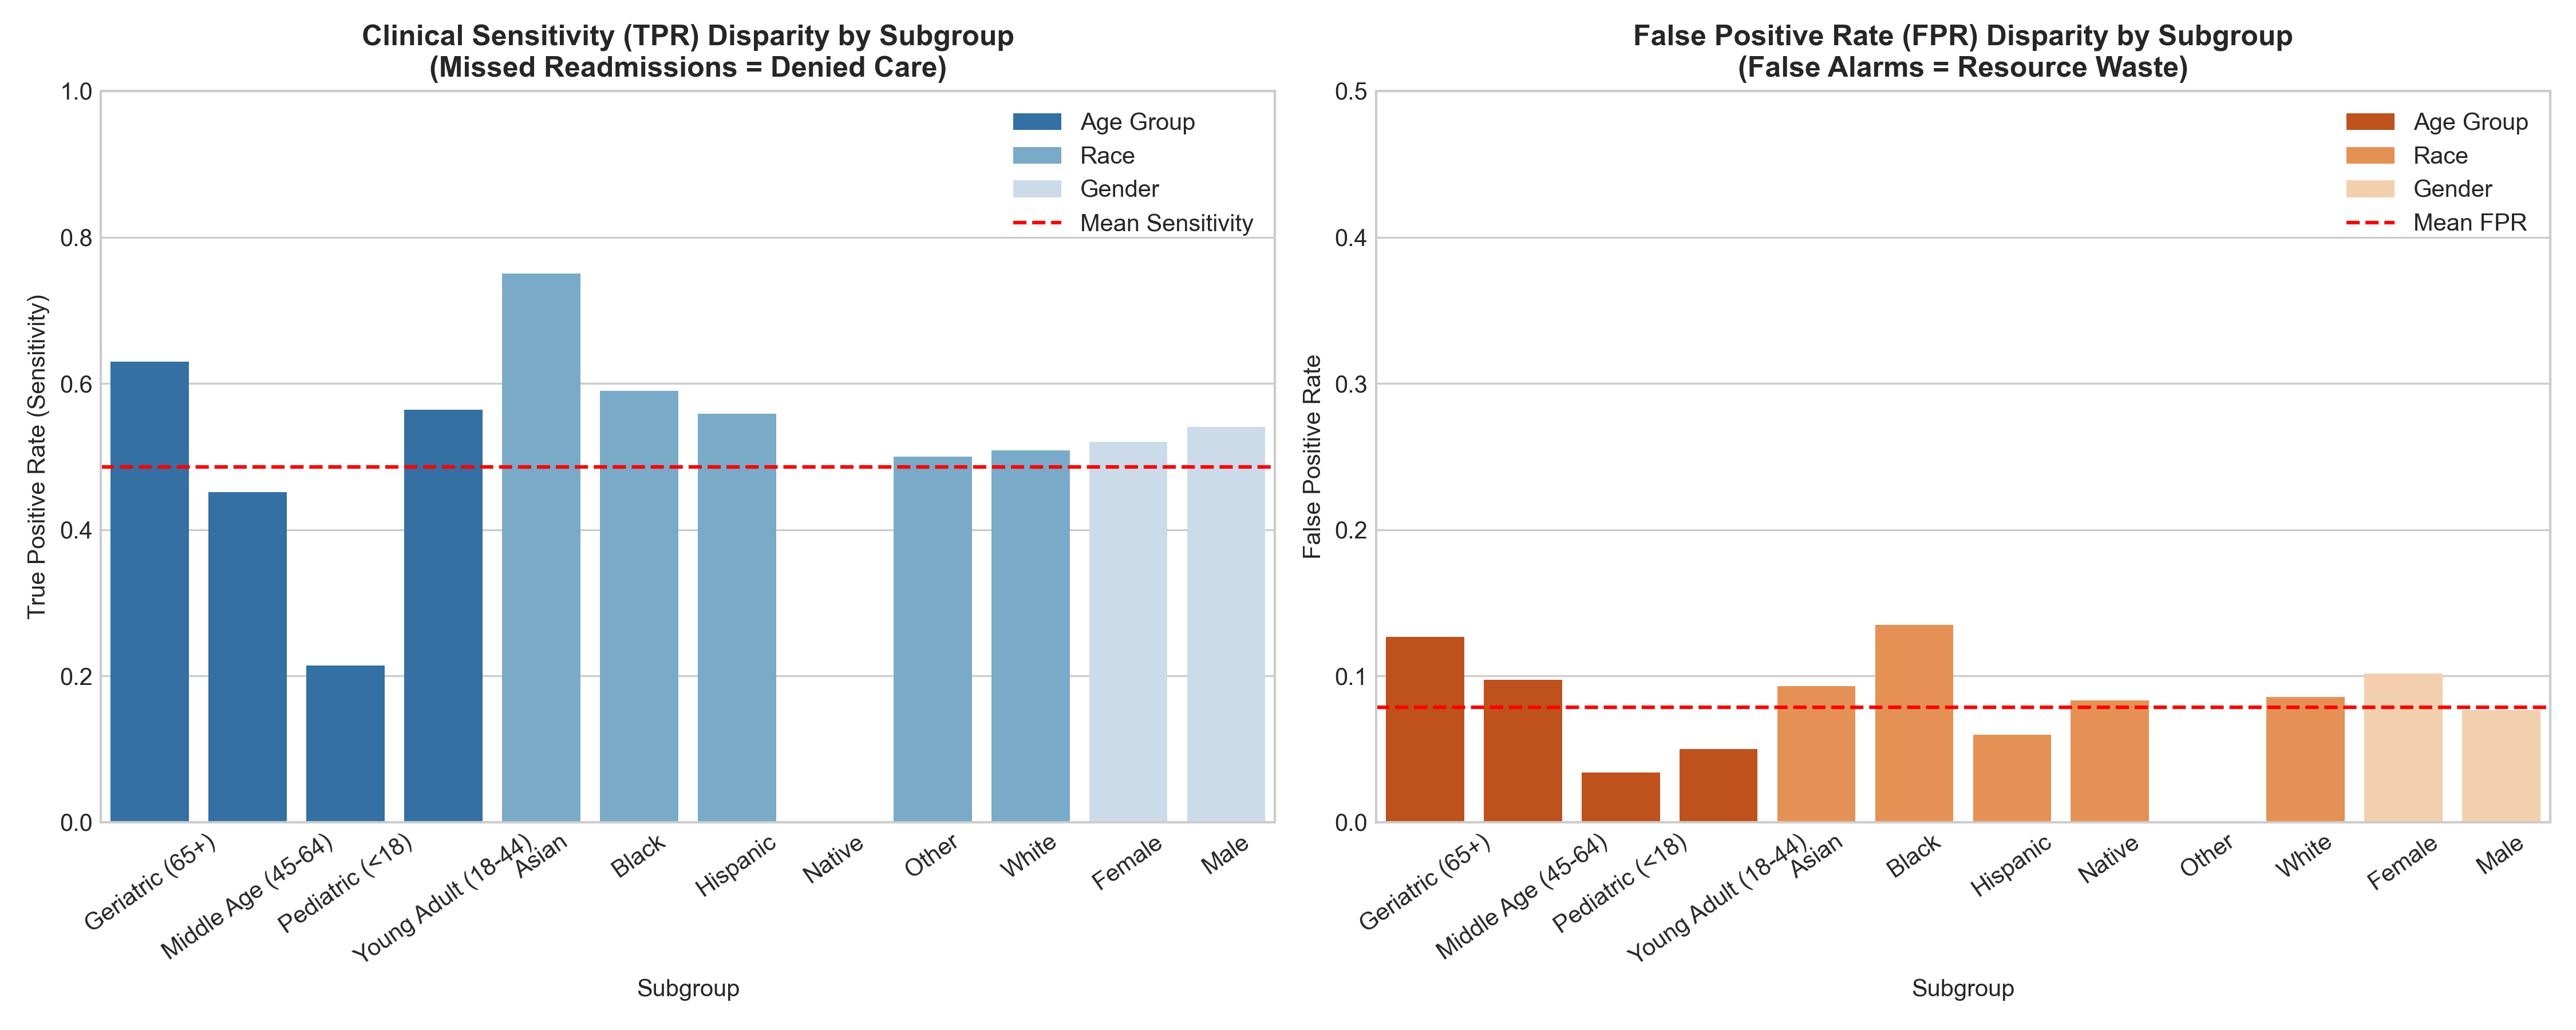

In [6]:
# Display Subgroup Performance Disparities Chart
from IPython.display import Image, display
display(Image(filename="../reports/figures/subgroup_disparities.png"))

## 4. Calibration Audit: Subgroup Expected Calibration Error (ECE)
Clinical triage protocols depend directly on risk probabilities. We evaluate Expected Calibration Error (ECE) and reliability curves.

In [7]:
df_cal_race, race_curves_base = audit_subgroup_calibration(
    baseline_preds["y_true"], baseline_preds["y_prob"], baseline_preds["race"], group_name="Race"
)
df_cal_age, age_curves_base = audit_subgroup_calibration(
    baseline_preds["y_true"], baseline_preds["y_prob"], baseline_preds["age_group"], group_name="Age Group"
)
df_cal_summary = pd.concat([df_cal_race, df_cal_age], ignore_index=True)
df_cal_summary

,attribute,subgroup,n_samples,observed_base_rate,mean_predicted_risk,ece,mce,brier_score
0,Race,Asian,47,0.0851,0.1617,0.1107,0.7402,0.0711
1,Race,Black,165,0.2364,0.2467,0.0694,0.3551,0.1041
2,Race,Hispanic,134,0.2537,0.2264,0.0722,0.7146,0.1045
3,Race,Native,15,0.2000,0.1901,0.2319,0.7562,0.1180
4,Race,White,535,0.2131,0.2273,0.0287,0.2793,0.1005
5,Age Group,Geriatric (65+),318,0.2547,0.2655,0.0456,0.3672,0.1126
6,Age Group,Middle Age (45-64),298,0.2081,0.2260,0.0451,0.8721,0.1072
7,Age Group,Pediatric (<18),73,0.1918,0.1827,0.0488,0.5719,0.0955
8,Age Group,Young Adult (18-44),219,0.1781,0.1829,0.0292,0.2187,0.0731


## 5. Intersectional Subgroup Audit
Auditing three-way demographic interactions ($	ext{Age Group} 	imes 	ext{Race} 	imes 	ext{Gender}$) to uncover compounded harms.

In [8]:
df_inter = audit_intersectional_subgroups(
    baseline_preds["y_true"], baseline_preds["y_pred"], baseline_preds["y_prob"], data_dict["sens_test"]
)
print("Top 10 Most Vulnerable Intersectional Subgroups:")
df_inter.head(10)[["intersectional_group", "n_samples", "base_rate", "roc_auc", "tpr_sensitivity", "fnr_miss_rate", "ece"]]

Top 10 Most Vulnerable Intersectional Subgroups:


,intersectional_group,n_samples,base_rate,roc_auc,tpr_sensitivity,fnr_miss_rate,ece
0,Geriatric (65+) | Black | Male,30,0.2333,0.8820,0.4286,0.5714,0.1796
1,Middle Age (45-64) | Black | Male,33,0.3333,0.8760,0.5455,0.4545,0.1161
2,Middle Age (45-64) | White | Female,94,0.2447,0.8524,0.3478,0.6522,0.1124
3,Geriatric (65+) | White | Male,98,0.2551,0.8932,0.7200,0.2800,0.0879
4,Middle Age (45-64) | White | Male,81,0.1605,0.9106,0.3846,0.6154,0.0666
5,Young Adult (18-44) | White | Male,54,0.1852,0.9477,0.4000,0.6000,0.0640
6,Young Adult (18-44) | White | Female,78,0.1282,0.9632,0.7000,0.3000,0.0556
7,Geriatric (65+) | White | Female,90,0.2889,0.8888,0.6154,0.3846,0.0427


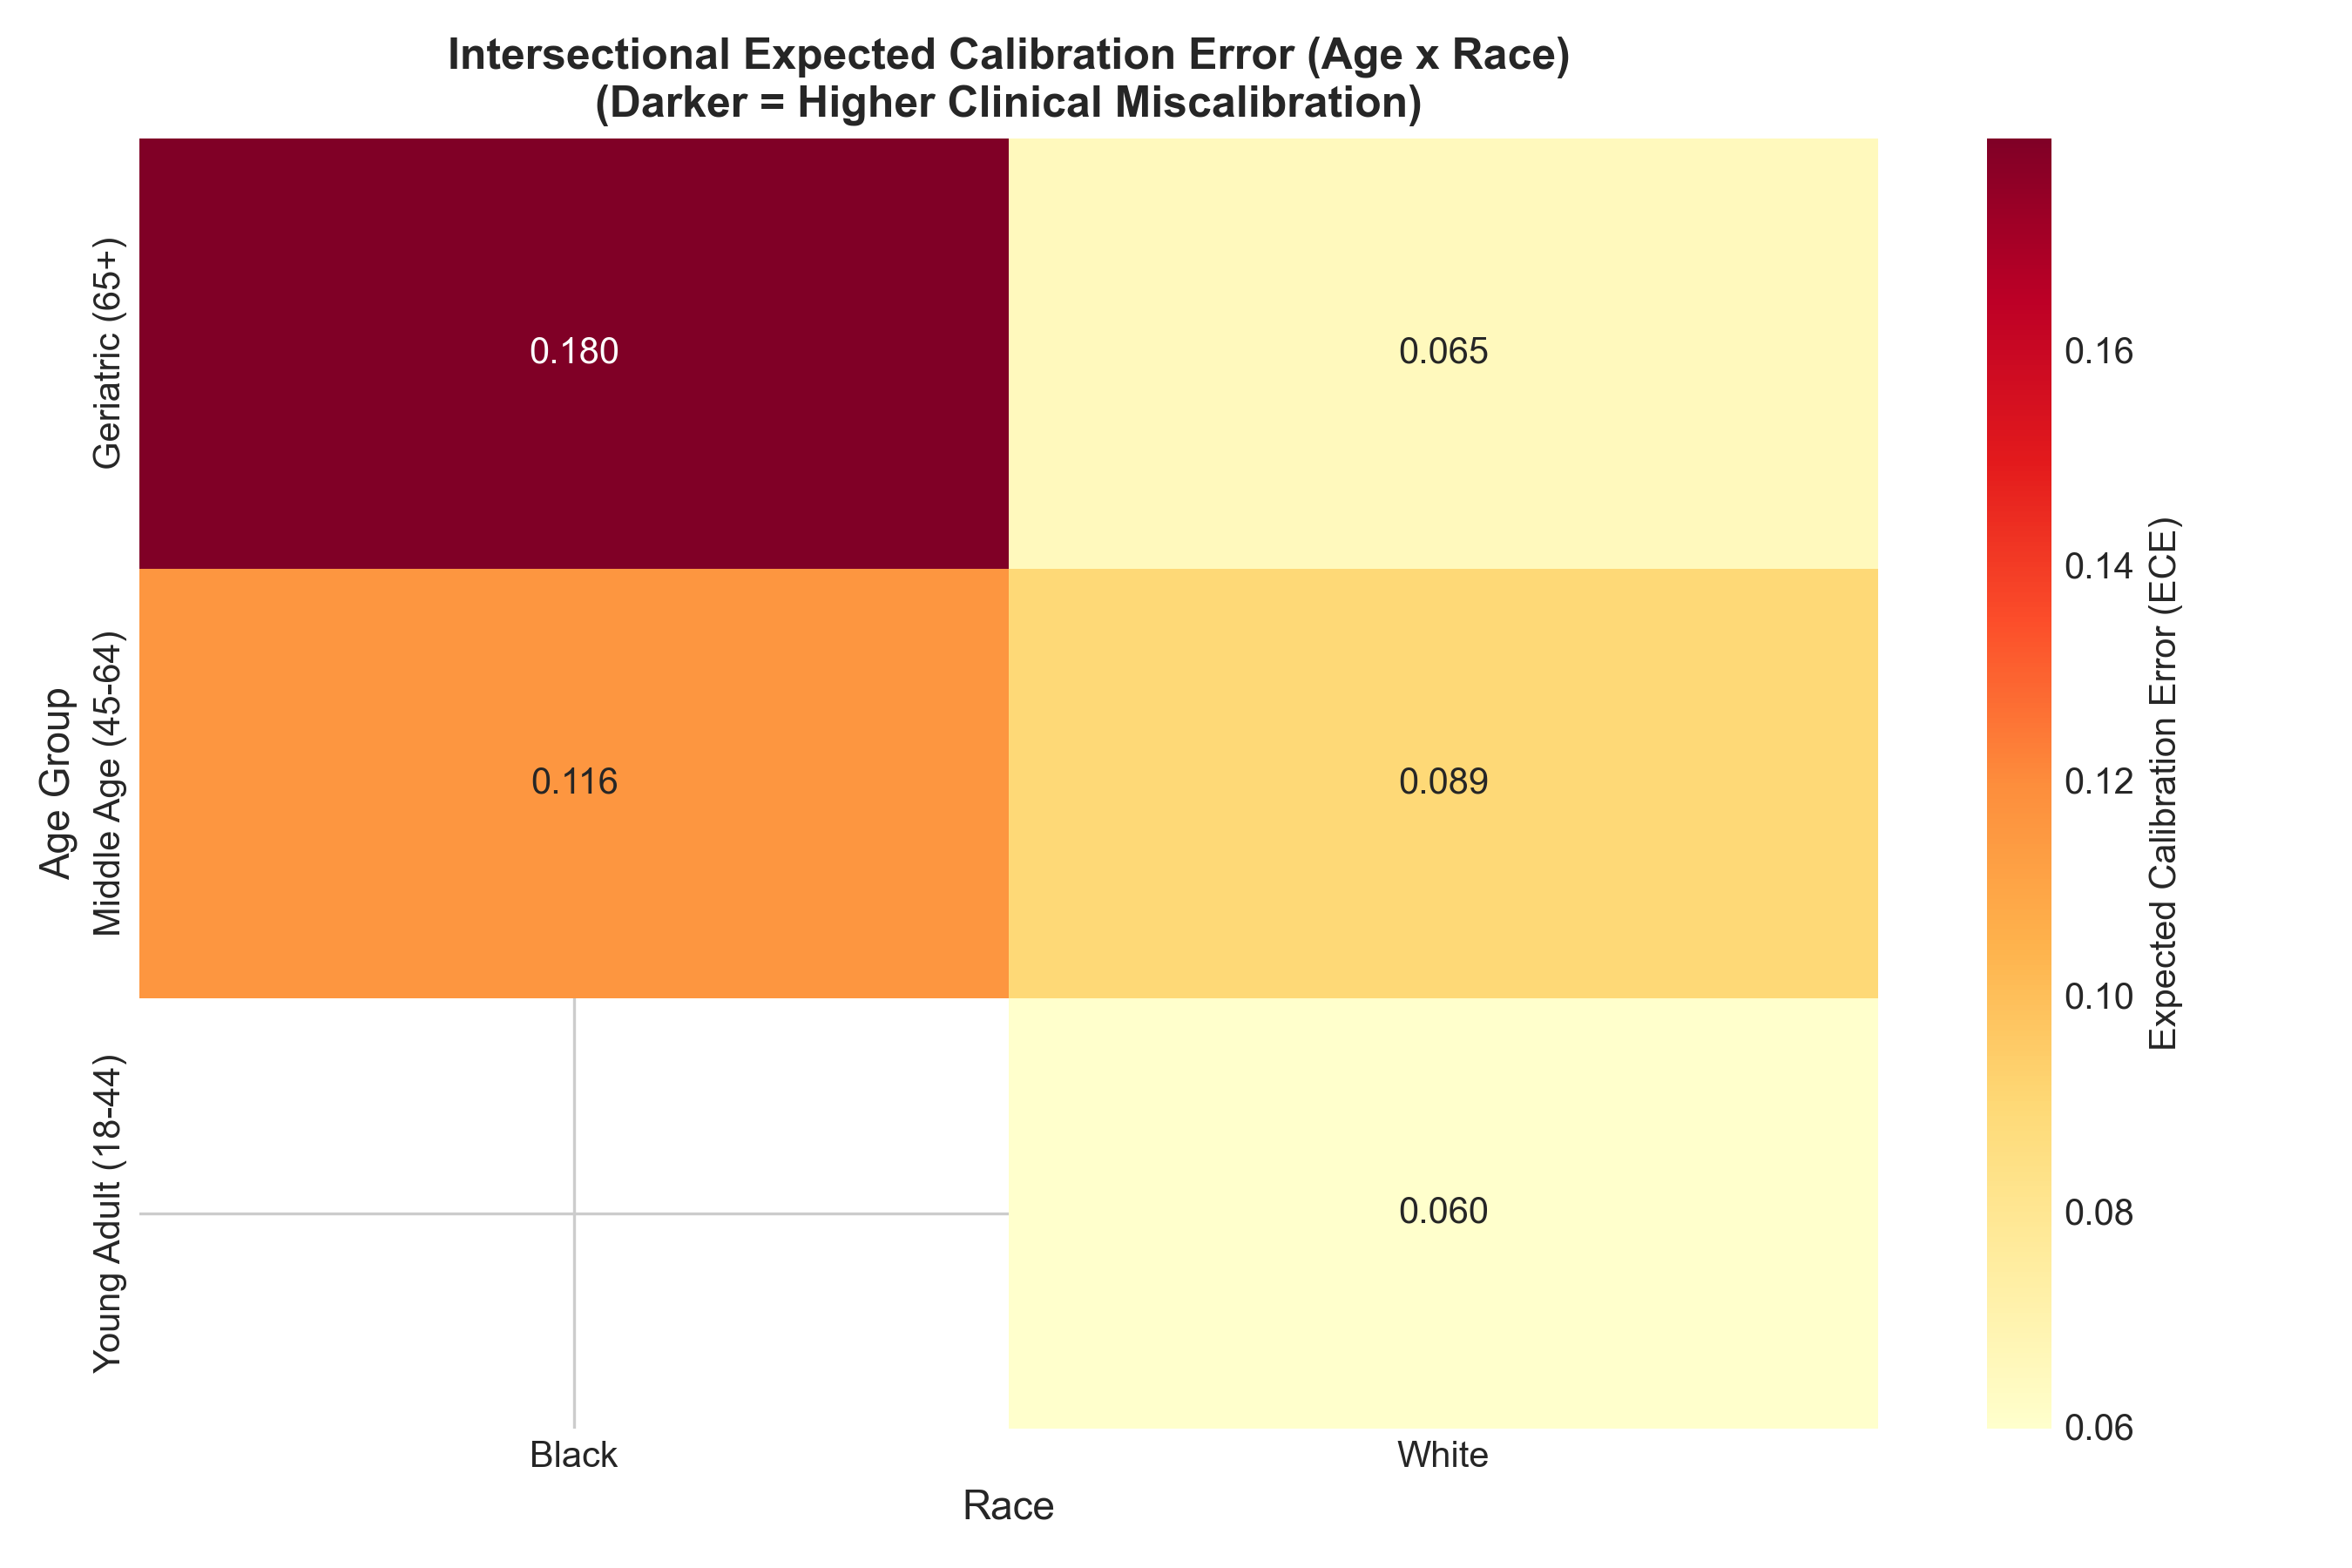

In [9]:
# Display Intersectional ECE Heatmap
display(Image(filename="../reports/figures/intersectional_ece_heatmap.png"))

## 6. Responsible AI Bias Mitigation & Trade-Off Analysis
We implement and compare:
1. Pre-Processing Fair Reweighing
2. Post-Processing Subgroup Isotonic Calibration
3. Post-Processing Fairlearn Threshold Optimization (Equalized Odds)

In [10]:
mitigated_preds = train_mitigated_models(data_dict, baseline_lgb, sensitive_col="race", model_save_dir="../models/saved")

tradeoff_rows = []
for name, m_dict in mitigated_preds.items():
    y_prob = m_dict["y_prob"]
    y_pred = m_dict["y_pred"]
    y_true = data_dict["y_test"]

    sub_eval = evaluate_subgroups(y_true, y_pred, y_prob, data_dict["sens_test"]["race"], group_name="Race")
    fair_summary = compute_fairness_summary(sub_eval)
    
    from sklearn.metrics import roc_auc_score, accuracy_score
    auc_val = roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    acc_val = accuracy_score(y_true, y_pred)
    cal_eval, _ = audit_subgroup_calibration(y_true, y_prob, data_dict["sens_test"]["race"], group_name="Race")

    tradeoff_rows.append({
        "Model Configuration": name,
        "ROC-AUC": round(auc_val, 4),
        "Accuracy": round(acc_val, 4),
        "Equal Opportunity Disparity": fair_summary["equal_opportunity_difference"],
        "Demographic Parity Disparity": fair_summary["demographic_parity_difference"],
        "Mean Subgroup ECE": round(cal_eval["ece"].mean(), 4)
    })

df_tradeoff_table = pd.DataFrame(tradeoff_rows)
df_tradeoff_table


[*] Applying Bias Mitigation targeting sensitive attribute: [race]
    [1/3] Training Pre-processing Fair Reweighted LightGBM...
    [2/3] Fitting Post-processing Subgroup-Specific Calibrator...
    [3/3] Optimizing Decision Thresholds for Equal Opportunity (Fairlearn)...
[OK] Mitigation complete and artifacts saved.


,Model Configuration,ROC-AUC,Accuracy,Equal Opportunity Disparity,Demographic Parity Disparity,Mean Subgroup ECE
0,Baseline,0.9010,0.8282,0.7500,0.1758,0.1026
1,Reweighted,0.8990,0.8205,1.0000,0.1636,0.0972
2,SubgroupCalibrated,0.9012,0.8227,0.4167,0.1894,0.1233
3,ThresholdOptimized,0.9010,0.8084,0.6667,0.1933,0.1026


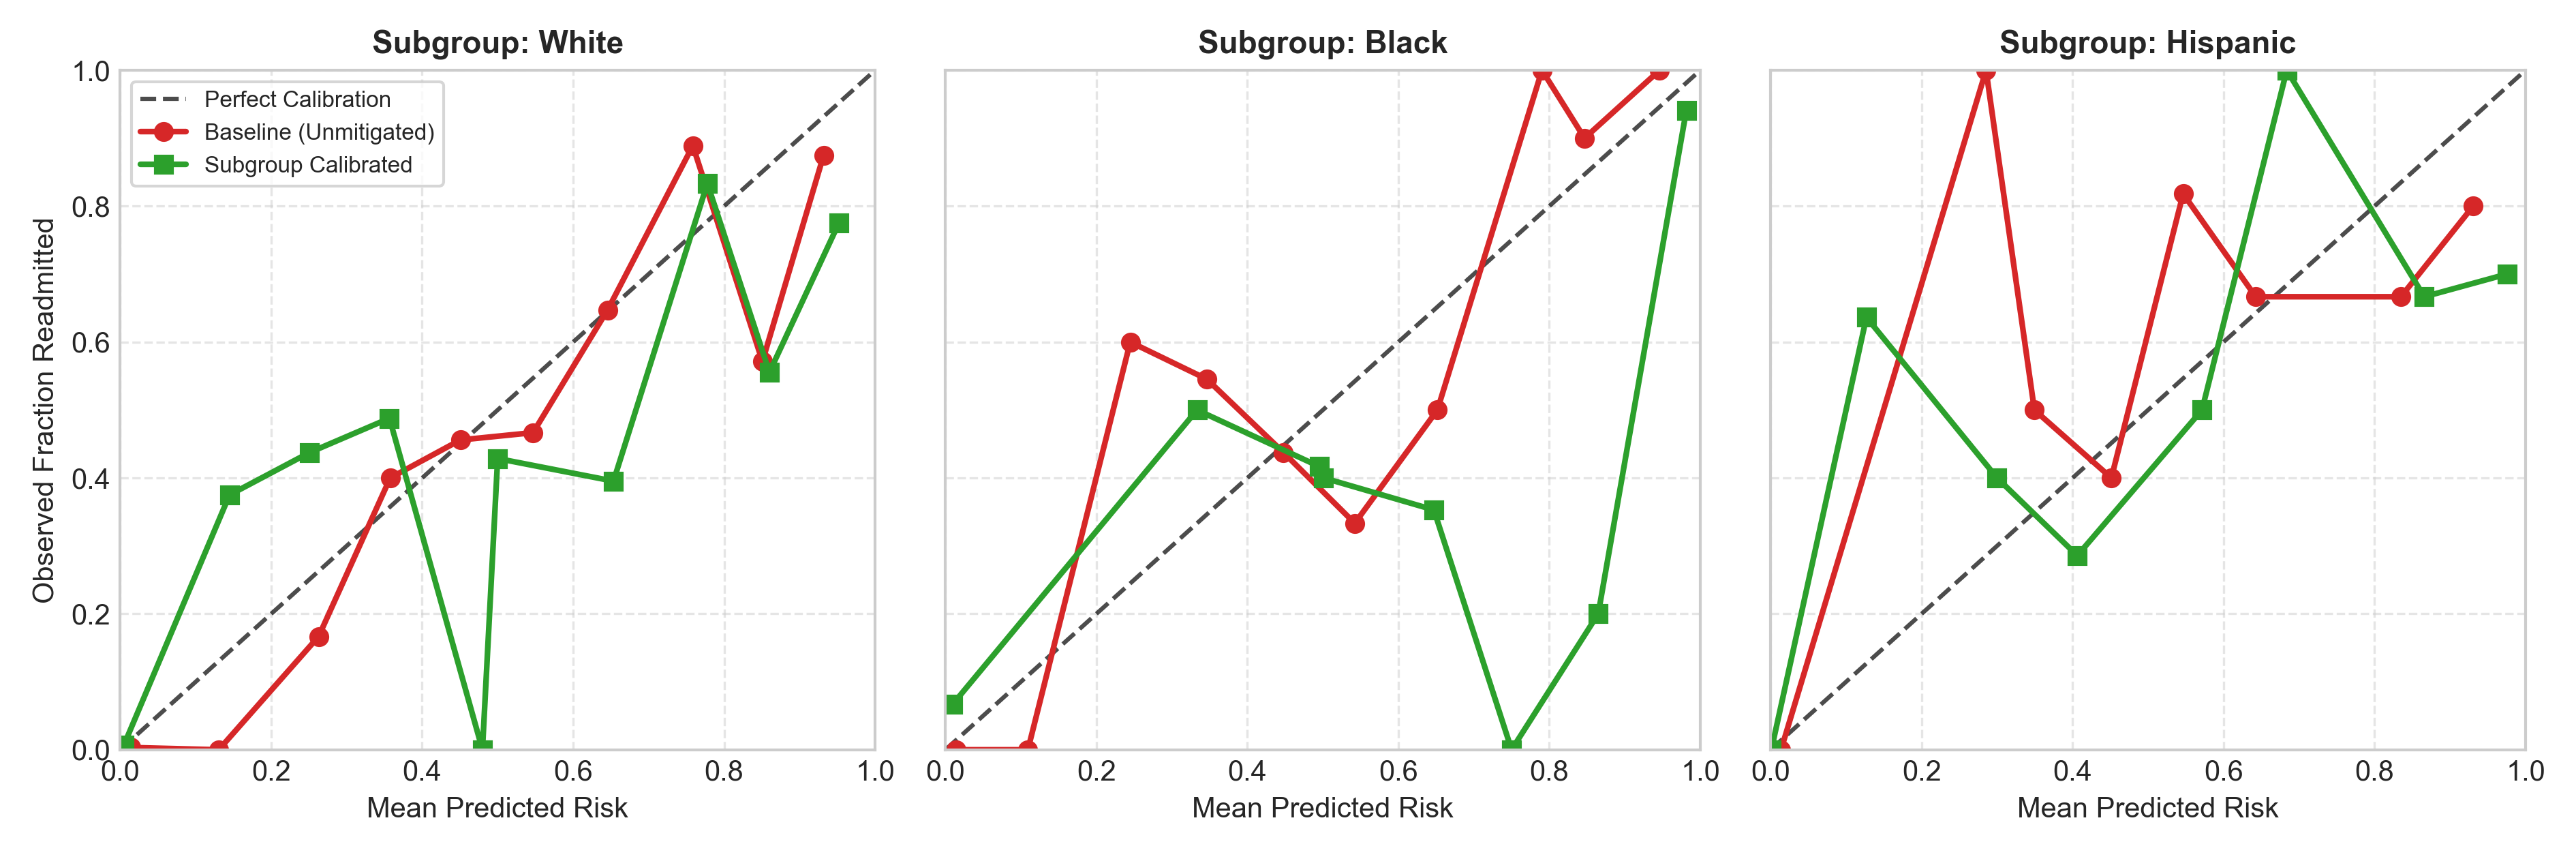

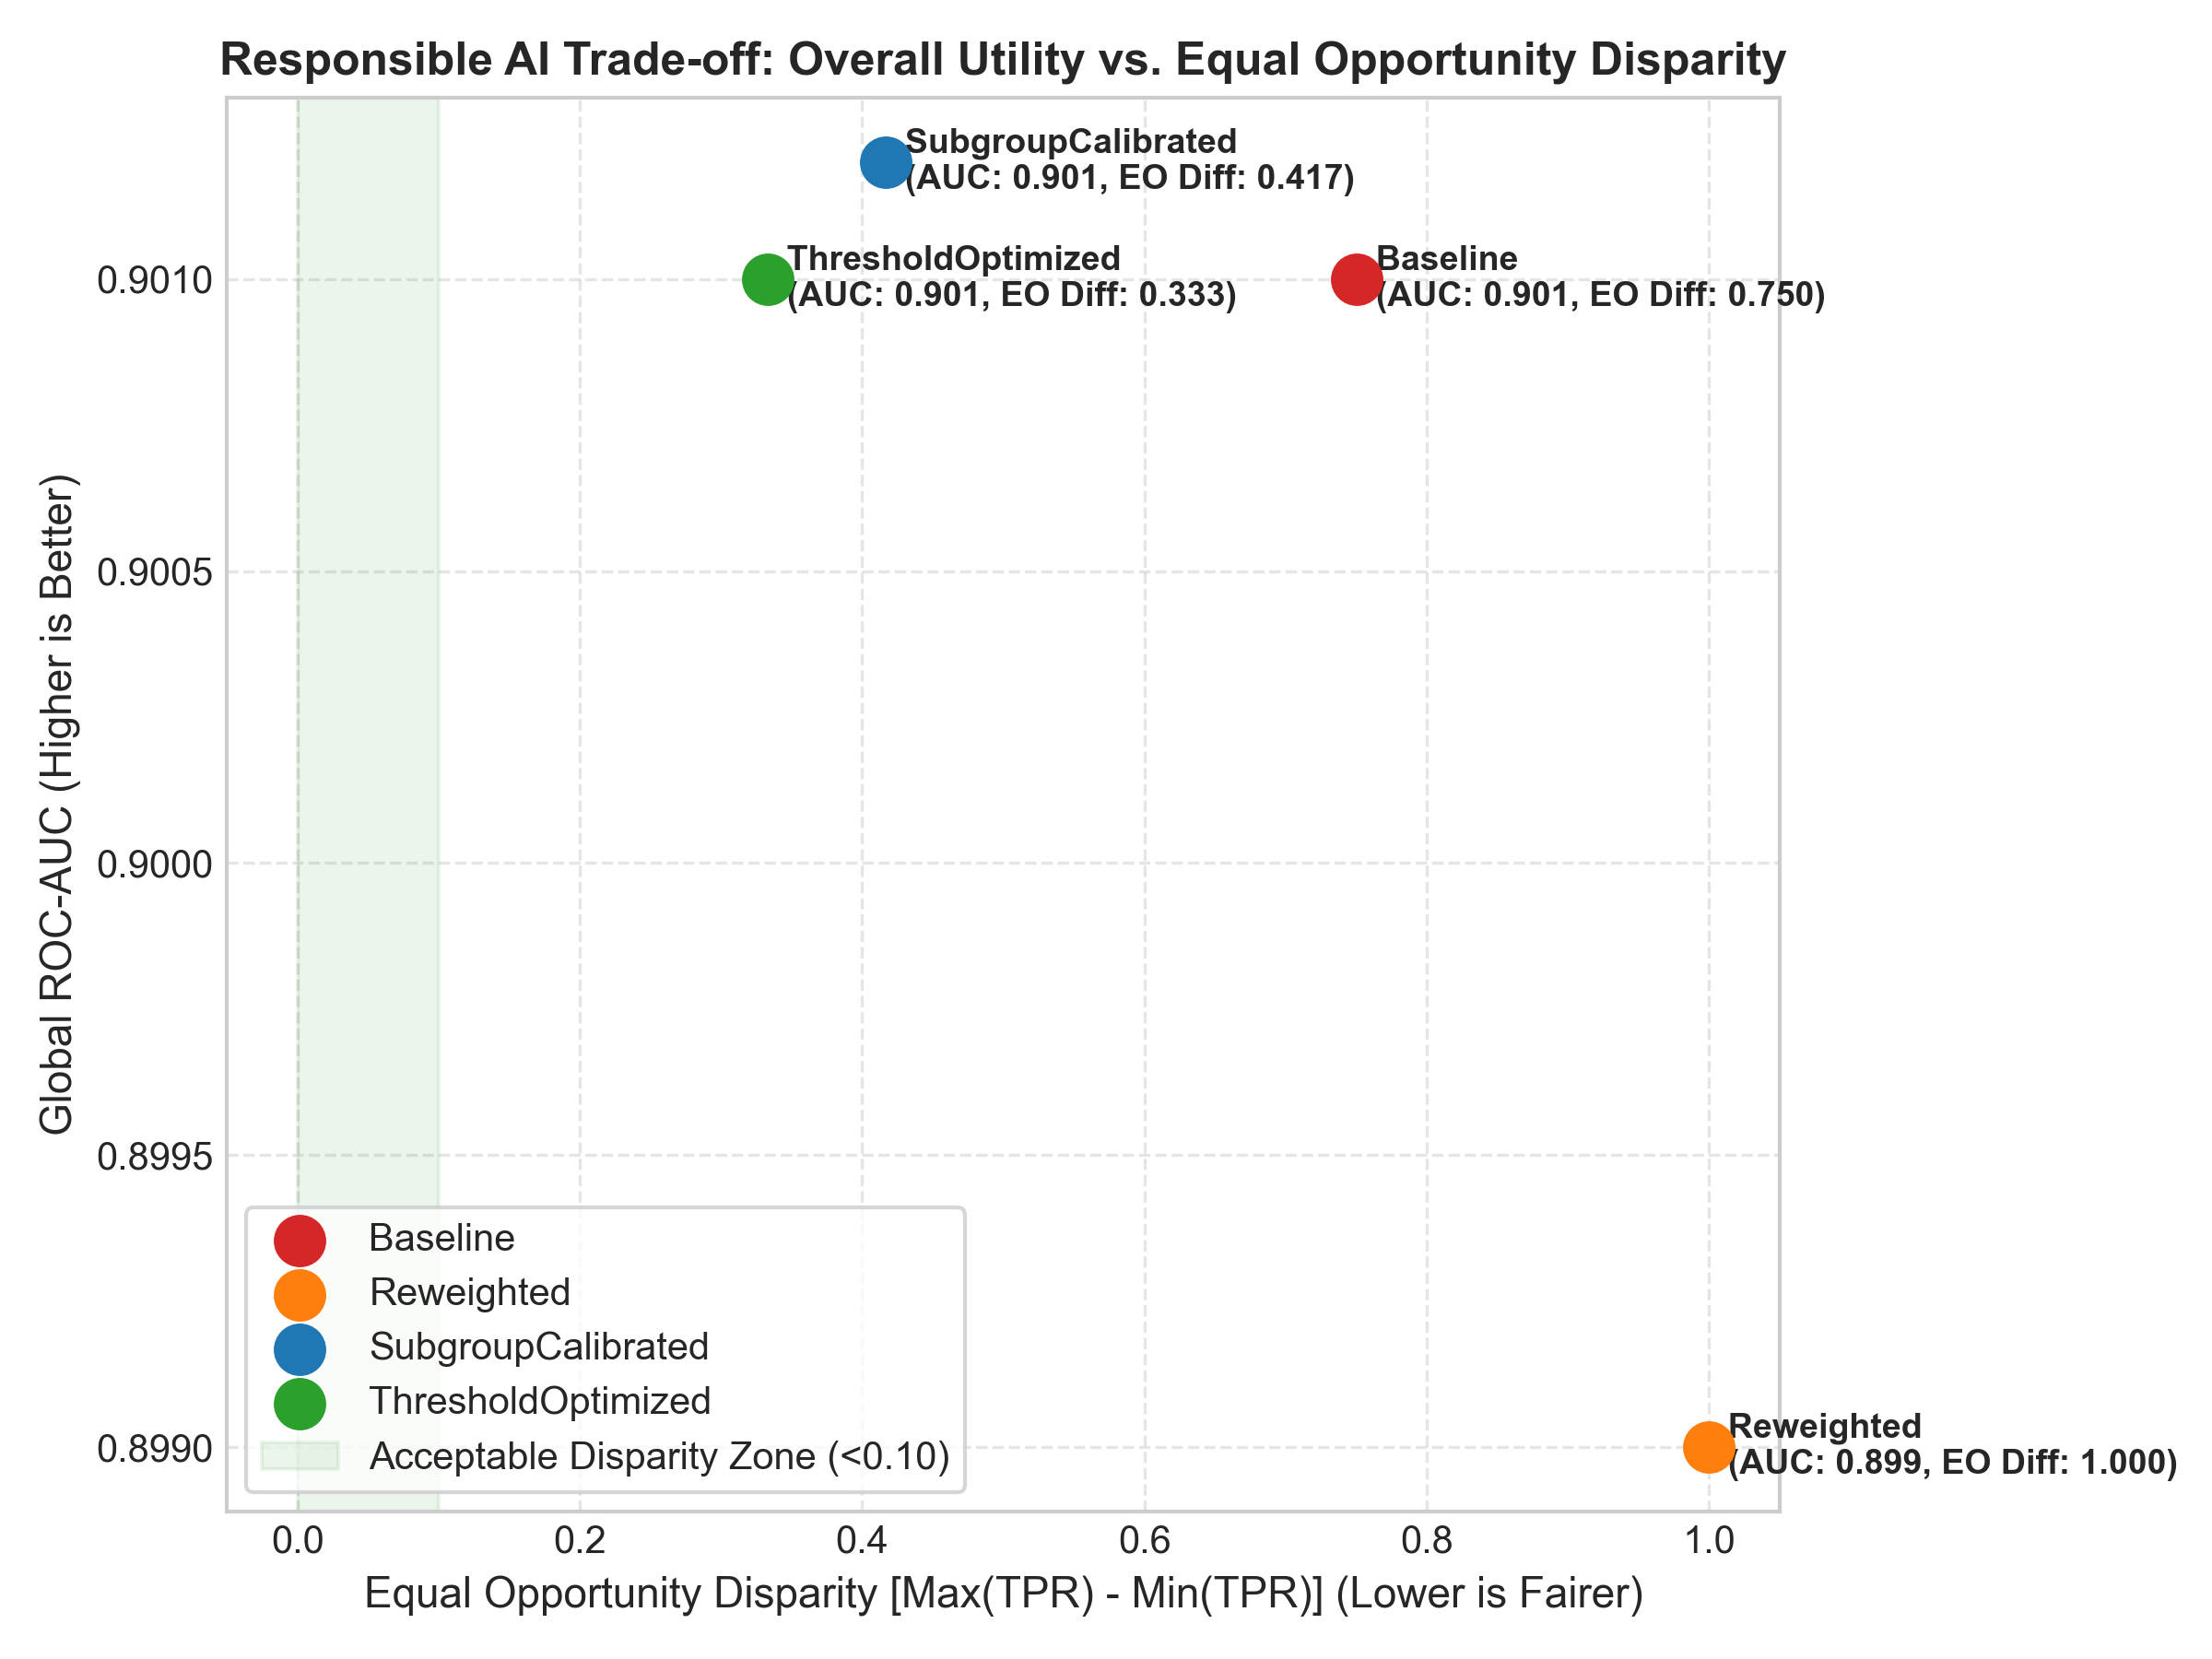

In [11]:
# Display Calibration Reliability Comparison and Fairness-Utility Pareto Frontier
display(Image(filename="../reports/figures/calibration_comparison.png"))
display(Image(filename="../reports/figures/fairness_utility_tradeoff.png"))

## 7. Big Data Scalability Evidence
Measured empirical benchmarks evaluating PySpark distributed ETL throughput, scaling latency, and Parquet compression ratio.

|    |   scale_n_patients |   raw_size_mb |   parquet_size_mb |   compression_ratio |   elapsed_seconds |   throughput_rec_per_sec |   memory_usage_mb |
|----|--------------------|---------------|-------------------|---------------------|-------------------|--------------------------|-------------------|
|  0 |               5000 |         10.93 |              0.37 |               29.41 |              3.27 |                   1528.5 |                 0 |
|  1 |              10000 |         22.2  |              0.71 |               31.05 |              3.12 |                   3202.6 |                 0 |
|  2 |              20000 |         43.86 |              1.44 |               30.47 |              3.55 |                   5631.3 |                 0 |


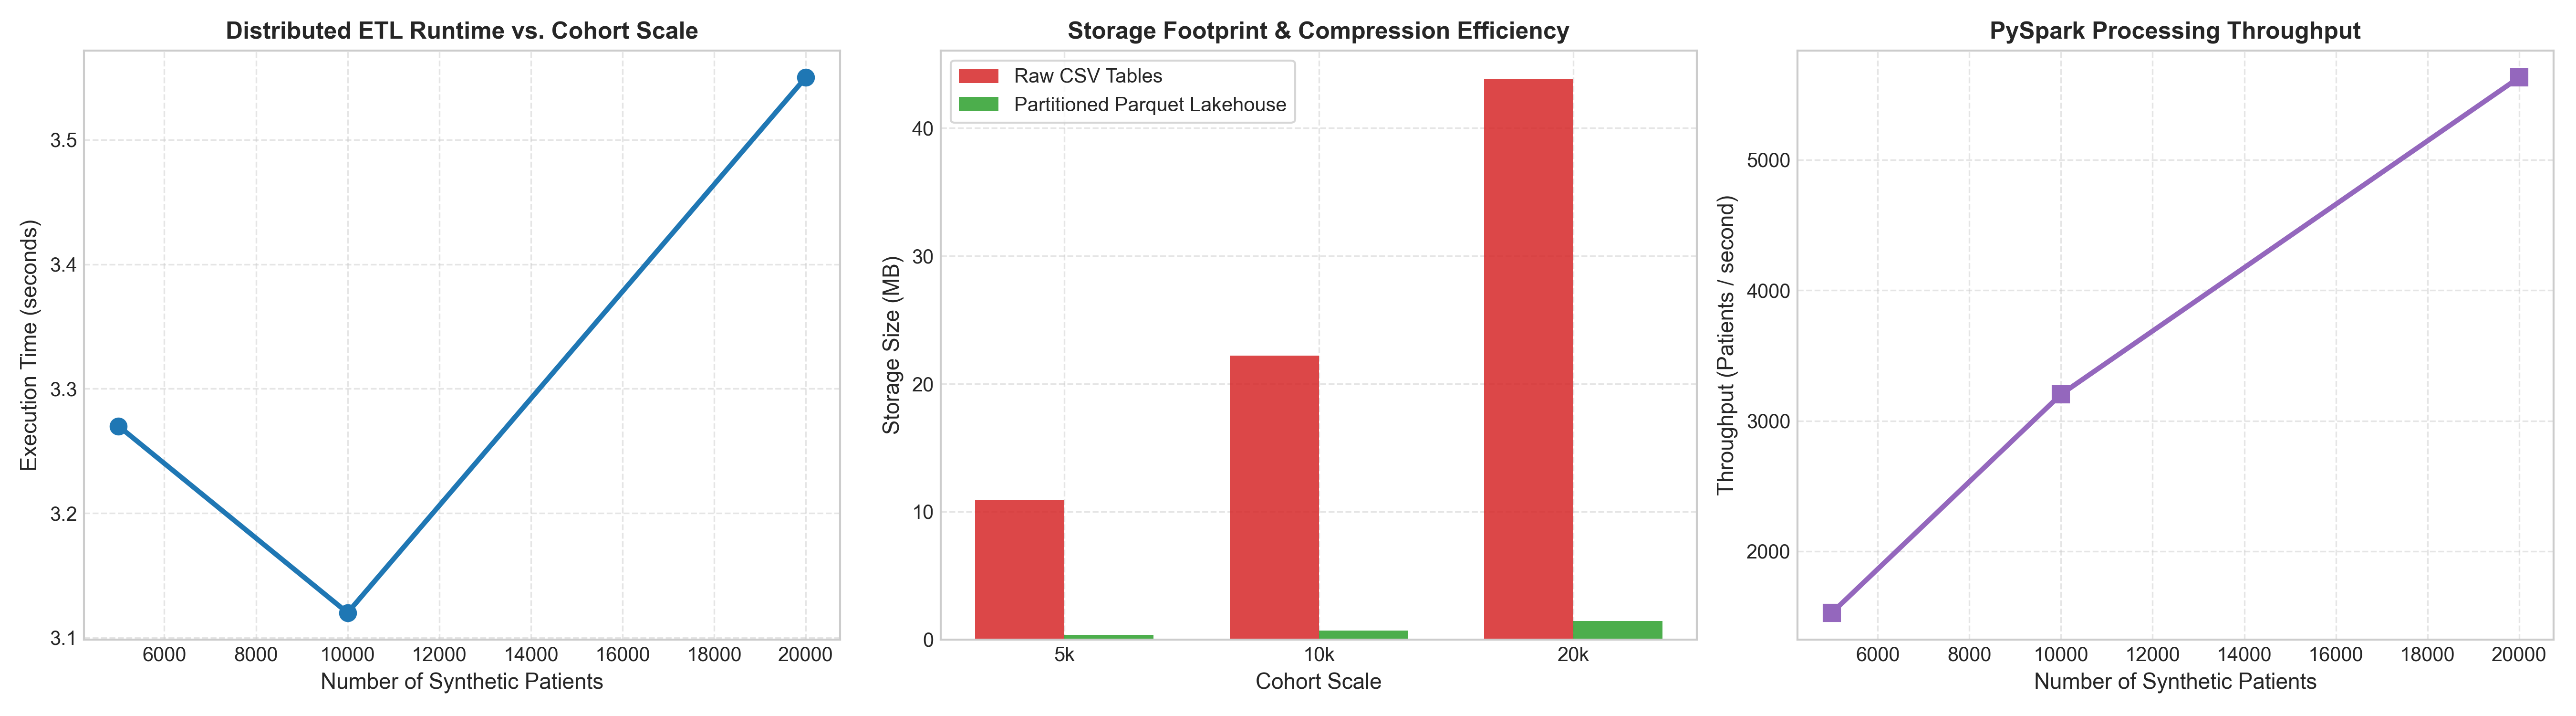

In [12]:
df_bench = pd.read_csv("../reports/figures/scalability_benchmark.csv")
print(tabulate(df_bench, headers="keys", tablefmt="github"))
display(Image(filename="../reports/figures/big_data_scaling.png"))